In [1]:
import sys
import os

# Set project root relative to notebook location
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from Losses import BiNormalLoss


In [2]:
import numpy as np
import mbtr.utils as ut
from scipy.linalg import hankel
from scipy.stats import expon
import matplotlib.pyplot as plt
from mbtr.mbtr import MBT
from mbtr.utils import set_figure
from mbtr import LOSS_MAP
from Losses.BiNormalLoss import BiNormalLikelihood

LOSS_MAP['binormal'] = BiNormalLikelihood # this line has to be added for the MBT class to recognize the JointExpLikelihood subclass as a type of loss

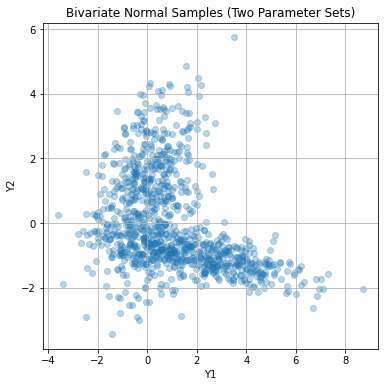

In [3]:
# Seed for reproducibility
np.random.seed(42)

# Number of samples
n = 100_000

# Step 1: Covariates
x = np.random.uniform(0, 1, n)
#X2 = np.random.uniform(0, 1, n)

# Step 2: Grouping
group_A = (x < 0.5)
group_B = ~group_A

# Step 3: Define parameters

# Group A
mu_A = np.array([0, 1])
std_A = np.array([1, 1.5])
rho_A = 0.3
cov_A = np.array([
    [std_A[0]**2, rho_A * std_A[0] * std_A[1]],
    [rho_A * std_A[0] * std_A[1], std_A[1]**2]
])

# Group B
mu_B = np.array([2, -1])
std_B = np.array([2, 0.5])
rho_B = -0.6
cov_B = np.array([
    [std_B[0]**2, rho_B * std_B[0] * std_B[1]],
    [rho_B * std_B[0] * std_B[1], std_B[1]**2]
])

# Step 4: Generate samples for each group
n_A = group_A.sum()
n_B = group_B.sum()

samples_A = np.random.multivariate_normal(mean=mu_A, cov=cov_A, size=n_A)
samples_B = np.random.multivariate_normal(mean=mu_B, cov=cov_B, size=n_B)

# Step 5: Combine
Y = np.zeros((n, 2))
Y[group_A] = samples_A
Y[group_B] = samples_B

Y1, Y2 = Y[:, 0], Y[:, 1]

# ✅ Done. Y1 and Y2 now come from group-dependent bivariate normals.

# Optional: visualize
plt.figure(figsize=(6, 6))
plt.scatter(Y1[:1000], Y2[:1000], alpha=0.3)
plt.title("Bivariate Normal Samples (Two Parameter Sets)")
plt.xlabel("Y1")
plt.ylabel("Y2")
plt.grid(True)
plt.show()


In [4]:
x = x.reshape(-1,1)
y = np.vstack((Y1, Y2)).T
m = MBT(loss_type = "binormal", n_boosts = 20, min_leaf = 1000, refit=False, lambda_weights=0, lambda_leaves=0, learning_rate=0.5).fit(x, y, do_plot=False)

100%|██████████| 20/20 [05:44<00:00, 17.23s/it]

#---------------- Model fitted in 5.75e+00 min ----------------


In [10]:
loss = BiNormalLikelihood()
tpar = m.predict(x)
par = np.hstack((tpar[:, 0].reshape(-1,1), np.exp(tpar[:, 1].reshape(-1,1)), tpar[:, 2].reshape(-1,1), np.exp(tpar[:, 3].reshape(-1,1)), loss.cop_par_inv_link(tpar[:, -1].reshape(-1,1))))

(array([  87.,    0.,  144.,   60.,  517.,  368.,  428.,  888., 1268.,
        1646., 2083., 2906., 3496., 3790., 3234., 4619., 4098., 4169.,
        4057., 2762., 2755., 1844., 1390., 1061.,  737.,  560.,  523.,
         335.,   67.,   42.]),
 array([-0.46895576, -0.44864583, -0.42833589, -0.40802595, -0.38771602,
        -0.36740608, -0.34709614, -0.32678621, -0.30647627, -0.28616634,
        -0.2658564 , -0.24554646, -0.22523653, -0.20492659, -0.18461666,
        -0.16430672, -0.14399678, -0.12368685, -0.10337691, -0.08306697,
        -0.06275704, -0.0424471 , -0.02213717, -0.00182723,  0.01848271,
         0.03879264,  0.05910258,  0.07941251,  0.09972245,  0.12003239,
         0.14034232]),
 <BarContainer object of 30 artists>)

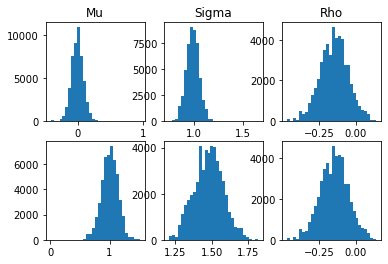

In [88]:
#plt.hist(par[group_A, 3], bins = 20)
#plt.show()
group = group_A
fig, axs = plt.subplots(2, 3)
axs[0, 0].hist(par[group, 0], bins = 30)
axs[0, 0].set_title('Mu')
axs[0, 1].hist(par[group, 1], bins = 30)
axs[0, 1].set_title('Sigma')
axs[0, 2].hist(par[group, -1], bins = 30)
axs[0, 2].set_title('Rho')
axs[1, 0].hist(par[group, 2], bins = 30)
#axs[1, 0].set_title('Axis [1, 0]')
axs[1, 1].hist(par[group, 3], bins = 30)
#axs[1, 1].set_title('Axis [1, 1]')
axs[1, 2].hist(par[group, -1], bins = 30)

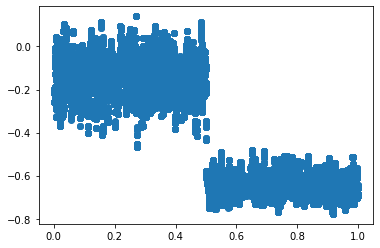

In [14]:
plt.scatter(x, par[:, -1])
plt.show()

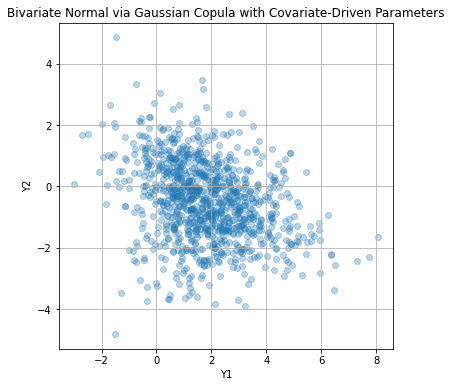

In [15]:
from scipy.stats import norm

# Seed for reproducibility
np.random.seed(42)

# Number of samples
n = 100_000

# Step 1: Generate 3 covariates (Uniform for generality)
X = np.random.uniform(0, 1, size=(n, 3))  # X1, X2, X3
X1, X2, X3 = X[:, 0], X[:, 1], X[:, 2]

# Step 2: Define GLM-like parameter functions

# Means (identity link)
mu1 = 1 + 2 * X1 - X2 + 0.5 * X3
mu2 = -1 + X1 + X2 - X3

# Standard deviations (log link → positive scale)
sigma1 = np.exp(0.2 + 0.5 * X1 - 0.3 * X2)
sigma2 = np.exp(-0.1 + 0.4 * X2 + 0.2 * X3)

# Correlation (tanh link → maps to [-1, 1])
linear_corr = -1 + 2 * X3 - X1
rho = np.tanh(linear_corr)

# Step 3: Construct Gaussian copula samples

# Standard normal samples (independent)
Z1 = np.random.normal(size=n)
Z2_indep = np.random.normal(size=n)

# Apply Gaussian copula formula: Z2 = rho * Z1 + sqrt(1 - rho^2) * ε
Z2 = rho * Z1 + np.sqrt(1 - rho**2) * Z2_indep

# Convert to uniforms
U1 = norm.cdf(Z1)
U2 = norm.cdf(Z2)

# Step 4: Apply inverse normal CDF with group-specific marginals
Y1 = norm.ppf(U1, loc=mu1, scale=sigma1)
Y2 = norm.ppf(U2, loc=mu2, scale=sigma2)

# ✅ Done! Y1 and Y2 now depend on X1–X3 via GLM-style parameter functions

# Optional: visualize a small sample
plt.figure(figsize=(6, 6))
plt.scatter(Y1[:1000], Y2[:1000], alpha=0.3)
plt.title("Bivariate Normal via Gaussian Copula with Covariate-Driven Parameters")
plt.xlabel("Y1")
plt.ylabel("Y2")
plt.grid(True)
plt.show()

In [23]:
import pandas as pd
import seaborn as sns
from scipy.stats import norm, rankdata, spearmanr
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Simulated data from earlier (assume you already have this)
# X (n x 3), Y1, Y2

# Create DataFrame for modeling
df = pd.DataFrame({
    'X1': X[:, 0],
    'X2': X[:, 1],
    'X3': X[:, 2],
    'Y1': Y1,
    'Y2': Y2
})

# ---------------------------
# STEP 1: Estimate Means (OLS)
# ---------------------------
model_mu1 = smf.ols('Y1 ~ X1 + X2 + X3', data=df).fit()
model_mu2 = smf.ols('Y2 ~ X1 + X2 + X3', data=df).fit()

# -------------------------------
# STEP 2: Estimate Std Dev (Gamma)
# -------------------------------
# First compute residuals from mean model
df['resid1'] = df['Y1'] - model_mu1.fittedvalues
df['resid2'] = df['Y2'] - model_mu2.fittedvalues

# Model squared residuals (proxy for variance)
df['var1'] = df['resid1']**2
df['var2'] = df['resid2']**2

# Use Gamma GLM on variances
model_var1 = smf.glm('var1 ~ X1 + X2 + X3', data=df,
                     family=sm.families.Gamma(link=sm.families.links.log())).fit()

model_var2 = smf.glm('var2 ~ X1 + X2 + X3', data=df,
                     family=sm.families.Gamma(link=sm.families.links.log())).fit()

# -------------------------------
# STEP 3: Estimate Correlation (GLM)
# -------------------------------

# Rank-transform Y1, Y2 to uniforms
U1 = rankdata(Y1) / (len(Y1) + 1)
U2 = rankdata(Y2) / (len(Y2) + 1)

# Inverse normal transform to get pseudo-normal
Z1 = norm.ppf(U1)
Z2 = norm.ppf(U2)

# Local (windowed) correlation estimation
df['Z1'] = Z1
df['Z2'] = Z2
df['rho'] = df['Z1'] * df['Z2']

# Fit linear model on Fisher-transformed correlation
df['fisher'] = np.arctanh(df['rho'].clip(-0.99, 0.99))  # Stabilize

model_rho = smf.ols('fisher ~ X1 + X2 + X3', data=df).fit()

In [17]:
# True data generation logic (from earlier)
mu1_true = 1 + 2 * X1 - X2 + 0.5 * X3
mu2_true = -1 + X1 + X2 - X3
sigma1_true = np.exp(0.2 + 0.5 * X1 - 0.3 * X2)
sigma2_true = np.exp(-0.1 + 0.4 * X2 + 0.2 * X3)
rho_true = np.tanh(-1 + 2 * X3 - X1)


In [18]:
df['mu1_true'] = mu1_true
df['mu2_true'] = mu2_true
df['sigma1_true'] = sigma1_true
df['sigma2_true'] = sigma2_true
df['rho_true'] = rho_true


In [21]:
def plot_true_vs_estimated_line(model, param_name, true_func, transform=None, n_points=100):
    """
    Plot the true parameter function as a line and estimated values as scatter points.
    true_func should take a vector x and return the true parameter value.
    """
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    for i, xi in enumerate(['X1', 'X2', 'X3']):
        ax = axes[i]

        # Scatter plot: estimated values
        estimated = model.fittedvalues
        if transform is not None:
            estimated = transform(estimated)
        sns.scatterplot(x=df[xi], y=estimated, label='Estimated', alpha=0.3, ax=ax)

        # Smooth line: true parameter relationship
        x_plot = np.linspace(0, 1, n_points)
        x_mean = {xj: df[xj].mean() for xj in ['X1', 'X2', 'X3']}
        true_vals = []

        for x_val in x_plot:
            x_mean[xi] = x_val
            X_vec = np.array([x_mean['X1'], x_mean['X2'], x_mean['X3']])
            true_val = true_func(X_vec)
            true_vals.append(true_val)

        ax.plot(x_plot, true_vals, color='black', lw=2, label='True')
        ax.set_title(f'{param_name} vs {xi}')
        ax.set_ylabel(param_name)
        ax.legend()

    plt.tight_layout()
    plt.show()


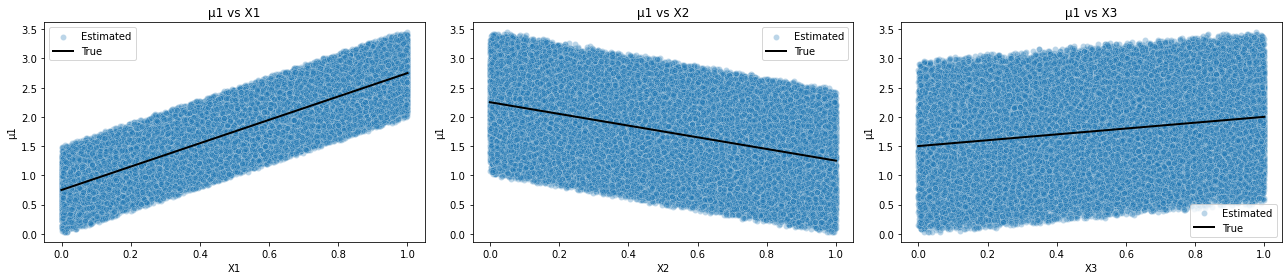

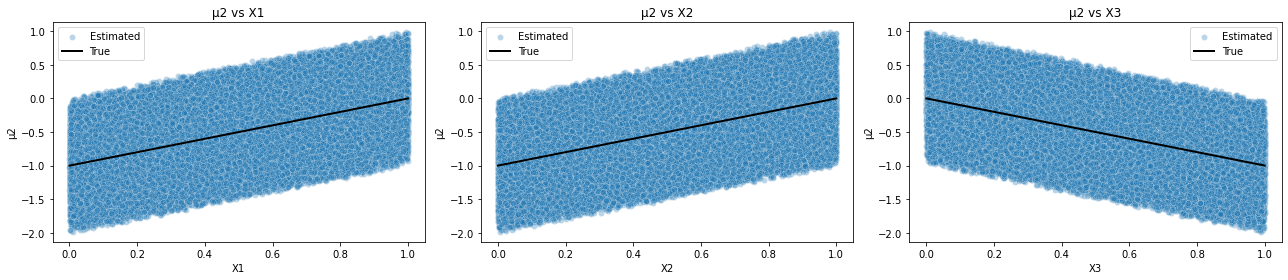

c:\Users\antho\anaconda3\lib\site-packages\IPython\core\pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


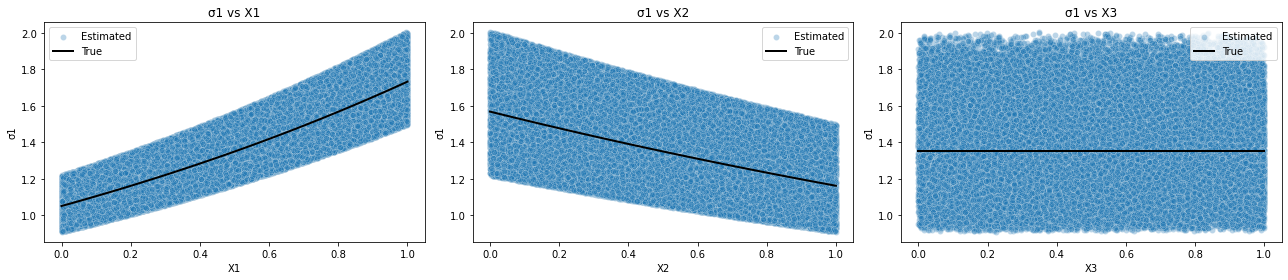

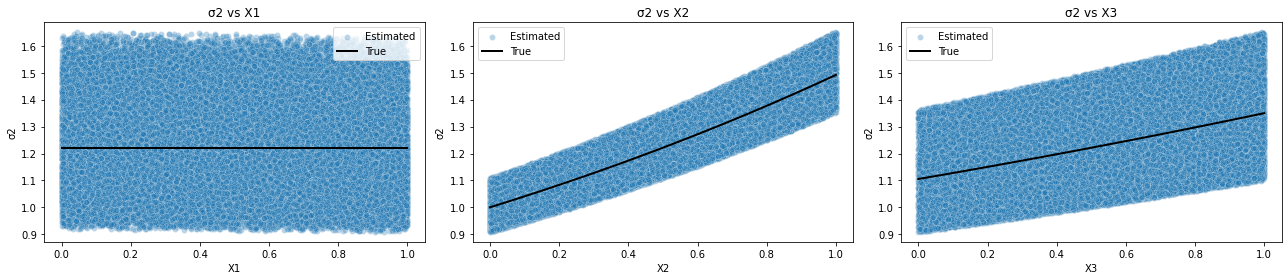

C:\Users\antho\AppData\Local\Temp\ipykernel_35868\60344119.py:33: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


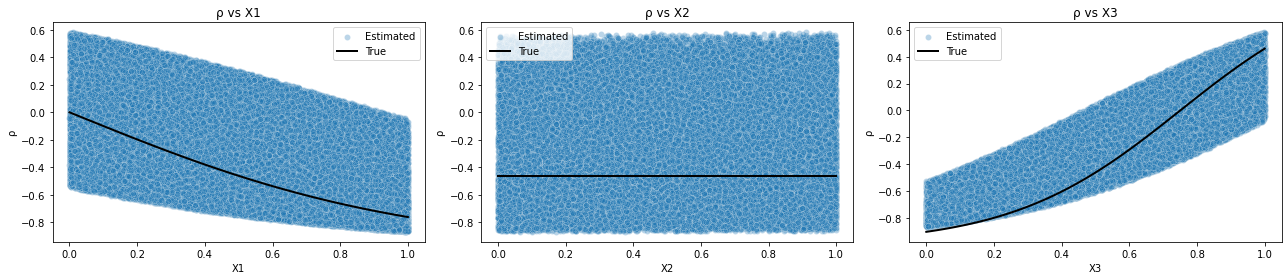

In [22]:
# Define true parameter functions
def mu1_func(x): return 1 + 2*x[0] - x[1] + 0.5*x[2]
def mu2_func(x): return -1 + x[0] + x[1] - x[2]
def sigma1_func(x): return np.exp(0.2 + 0.5*x[0] - 0.3*x[1])
def sigma2_func(x): return np.exp(-0.1 + 0.4*x[1] + 0.2*x[2])
def rho_func(x): return np.tanh(-1 + 2*x[2] - x[0])

# Mean
plot_true_vs_estimated_line(model_mu1, 'μ1', mu1_func)
plot_true_vs_estimated_line(model_mu2, 'μ2', mu2_func)

# Std dev (sqrt of predicted variance)
plot_true_vs_estimated_line(model_var1, 'σ1', sigma1_func, transform=lambda x: np.sqrt(x))
plot_true_vs_estimated_line(model_var2, 'σ2', sigma2_func, transform=lambda x: np.sqrt(x))

# Correlation (apply tanh to Fisher z estimate)
plot_true_vs_estimated_line(model_rho, 'ρ', rho_func, transform=np.tanh)


In [69]:
x_glm = np.vstack((X1, X2, X3)).T
y_glm = np.vstack((Y1, Y2)).T
m_glm = MBT(loss_type = "binormal", n_boosts = 20, min_leaf = 1000, refit=False, lambda_weights=0, lambda_leaves=0, learning_rate=0.5).fit(x_glm, y_glm, do_plot=False)

  0%|          | 0/20 [00:00<?, ?it/s]

100%|██████████| 20/20 [04:50<00:00, 14.52s/it]

#---------------- Model fitted in 4.84e+00 min ----------------


In [71]:
loss = BiNormalLikelihood()
tpar_glm = m_glm.predict(x_glm)
par_glm = np.hstack((tpar_glm[:, 0].reshape(-1,1), np.exp(tpar_glm[:, 1].reshape(-1,1)), tpar_glm[:, 2].reshape(-1,1), np.exp(tpar_glm[:, 3].reshape(-1,1)), loss.cop_par_inv_link(tpar_glm[:, -1].reshape(-1,1))))

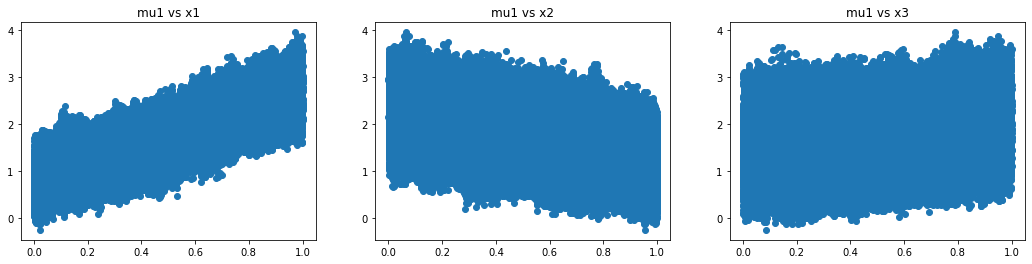

In [85]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].scatter(X1, par_glm[:, 0])
axes[0].set_title("mu1 vs x1")
axes[1].scatter(X2, par_glm[:, 0])
axes[1].set_title("mu1 vs x2")
axes[2].scatter(X3, par_glm[:, 0])
axes[2].set_title("mu1 vs x3")
plt.show()

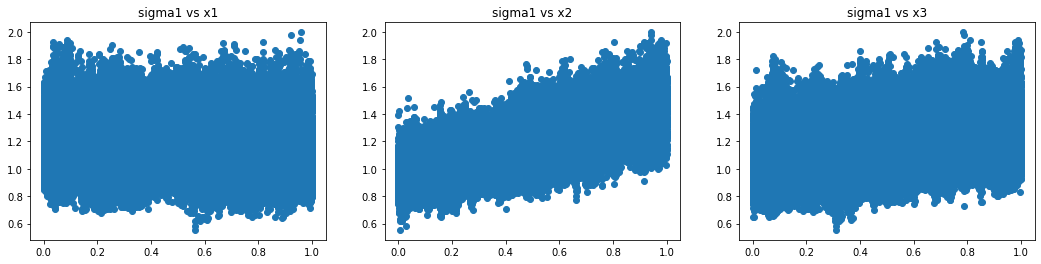

In [90]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].scatter(X1, par_glm[:, 3])
axes[0].set_title("sigma1 vs x1")
axes[1].scatter(X2, par_glm[:, 3])
axes[1].set_title("sigma1 vs x2")
axes[2].scatter(X3, par_glm[:, 3])
axes[2].set_title("sigma1 vs x3")
plt.show()

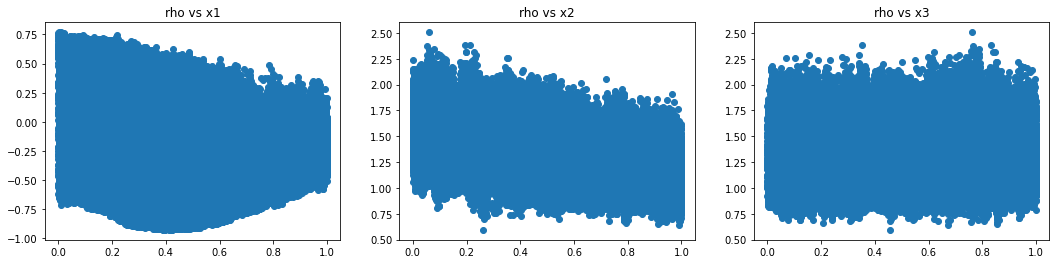

In [87]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].scatter(X1, par_glm[:, -1])
axes[0].set_title("rho vs x1")
axes[1].scatter(X2, par_glm[:, 1])
axes[1].set_title("rho vs x2")
axes[2].scatter(X3, par_glm[:, 1])
axes[2].set_title("rho vs x3")
plt.show()